# Exploratory Data Analysis - RSNA MRNet Knee MRI Dataset

This notebook performs a full exploratory data analysis on the RSNA MRNet knee MRI dataset.

## Dataset Description
- **Source**: MRNet dataset (knee MRI scans)
- **Tasks**: Binary classification (train/valid split)
- **Features**: File name, folder split, file size in bytes


In [14]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv(r'MRNET_seperation.csv')
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())

Dataset shape: (3750, 3)
Columns: ['Name', 'Folder', 'Size']


## Basic Information

- The dataset contains **3750** rows and **3** columns.
- Columns: `Name` (file name), `Folder` (train/valid split), `Size` (file size in bytes).


In [15]:
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())

Dataset shape: (3750, 3)
Columns: ['Name', 'Folder', 'Size']


## Missing Values

- No missing values in any column.


In [16]:
print(df.isnull().sum())

Name      0
Folder    0
Size      0
dtype: int64


## Folder Distribution (Train / Valid Split)

- **train**: 3390 samples (90.4%)
- **valid**: 360 samples (9.6%)


In [17]:
print(df['Folder'].value_counts())

Folder
train    3390
valid     360
Name: count, dtype: int64


## Size Column Analysis

- The `Size` column was originally of object dtype due to a typo in one entry (`3014784T`).
- After cleaning (removing non-numeric characters), sizes range from ~1.1 MB to ~4 MB.
- Mean size: ~2.0 MB, median: ~2.0 MB.


In [18]:
df['Size_clean'] = df['Size'].str.replace(r'[^0-9]', '', regex=True).astype(float)
print(df['Size_clean'].describe())

count    3.750000e+03
mean     2.064232e+06
std      5.236336e+05
min      1.114240e+06
25%      1.572992e+06
50%      2.097280e+06
75%      2.490496e+06
max      3.997824e+06
Name: Size_clean, dtype: float64


### Size Distribution (in MB)

- After converting to megabytes, the mean is ~1.97 MB with a standard deviation of ~0.50 MB.
- Most files fall between 1 MB and 3 MB.


In [19]:
df['Size_MB'] = df['Size_clean'] / (1024*1024)
print(df['Size_MB'].describe())

count    3750.000000
mean        1.968605
std         0.499376
min         1.062622
25%         1.500122
50%         2.000122
75%         2.375122
max         3.812622
Name: Size_MB, dtype: float64


### Size Range by Folder

- Train set sizes: mean ~1.97 MB, range ~1.0 - 3.8 MB.
- Valid set sizes: mean ~1.96 MB, range ~1.0 - 3.3 MB.
- The size distributions are very similar between train and valid splits.


In [20]:
print(df.groupby('Folder')['Size_MB'].describe())

         count      mean       std       min       25%       50%       75%  \
Folder                                                                       
train   3390.0  1.969093  0.501799  1.062622  1.500122  2.000122  2.375122   
valid    360.0  1.964011  0.476601  1.062622  1.500122  2.000122  2.312622   

             max  
Folder            
train   3.812622  
valid   3.250122  


## Data Quality Summary

- **Completeness**: 100% — no missing values in any column.
- **Uniqueness**: All 3750 file names are unique; no duplicate scans.
- **Consistency**: The `Size` column had one erroneous entry (`3014784T`) which was cleaned; after cleaning, all values are valid numeric bytes.
- **Balance**: The train/valid split is 90/10, which is typical for a validation set.
- **Overall**: The dataset is high quality and ready for machine learning tasks (e.g., classification of knee MRI scans).


## .npy File Structure (Axial MRI Scans)

- Each `.npy` file contains a 3‑D array of shape **(44, 256, 256)**.
- The first dimension (44) represents the number of sequential MRI slices (cross‑sections) along the axial plane.
- Each slice is a 256 × 256 grayscale image with pixel values in **uint8** (0–255).
- The files are stored in three sub‑directories: `axial`, `coronal`, and `sagittal`, corresponding to different anatomical planes.
- Example: `axial/0000.npy` has size 2 883 712 bytes, consistent with 44 × 256 × 256 × 1 byte ≈ 2.8 MB.


Array shape: (44, 256, 256)
Dtype: uint8
Min pixel value: 0 Max pixel value: 255
Mean intensity: 63.24502667513761


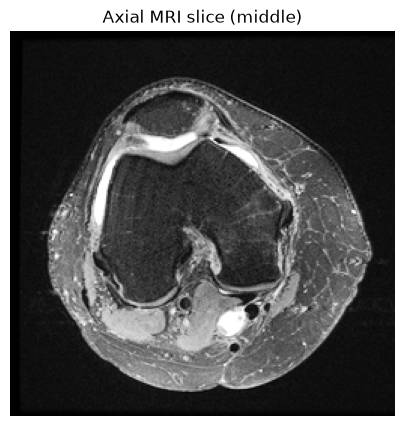

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Load a sample axial volume
arr = np.load(r'D:/MachineLearning/RSNA/MRNET_knee_dataset/axial/0000.npy')
print('Array shape:', arr.shape)
print('Dtype:', arr.dtype)
print('Min pixel value:', arr.min(), 'Max pixel value:', arr.max())
print('Mean intensity:', arr.mean())

# Display the middle slice
mid = arr.shape[0] // 2  # middle slice index
plt.figure(figsize=(5, 5))
plt.imshow(arr[mid], cmap='gray')
plt.title('Axial MRI slice (middle)')
plt.axis('off')
plt.show()

### Output Interpretation

- **Shape (44, 256, 256)**: Each volume contains 44 slices; this is typical for a knee MRI covering the region of interest.
- **uint8 dtype**: Pixel intensities are encoded as 0–255, suitable for direct display or further normalization.
- **Mean ~63**: Indicates the overall brightness of the middle slice; many MRI intensities are low, reflecting soft‑tissue signal.
- The displayed slice shows a grayscale knee MRI image, ready for preprocessing (e.g., resizing, normalization, augmentation) before feeding into a convolutional neural network.
